# Monte Carlo analysis of the docking

The closed-loop notebook flew the reference mission once, with nominal hardware, and the ports met with wide margins. One run is one sample. The thrusters of the real vehicle will not deliver exactly their nominal thrust, they will not be mounted exactly along the body axes, the center of mass will not be exactly on the thrust lines, the relative sensor will be mounted with a small error, the chief will not hold exactly its nominal attitude, and the deputy will not start exactly at its hold point. Each of these deviations is small and none can be known in advance.

A Monte Carlo campaign flies the mission many times, each time with its own draw of these quantities and its own sequence of sensor noise, and looks at the distribution of the results. It answers three questions that a single run cannot: how probable the success of the docking is, how the conditions at contact are distributed with respect to their limits, and how much propellant should be budgeted.

This is a different calculation from the collision probability of the safety chapter. That one propagated an initial uncertainty with the linear transition matrix and no corrections along the way, which is fast and pessimistic. This one flies the complete loop, in which the navigation measures and the controller corrects all the way to the port.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

import copy
import os
import time
from dataclasses import fields

from ios_mission_planner.sim.config import SimulationConfig
from ios_mission_planner.sim.monte_carlo import (
    CONTACT_QUANTITIES, Dispersions, run_monte_carlo, wilson_interval,
)
from ios_mission_planner.sim.simulator import simulate

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_ANA = "#1f77b4"
COL_NUM = "#d62728"
COL_ZONE = "#9467bd"

WORKERS = max(1, (os.cpu_count() or 2) // 2)

## What changes from one run to the next

`Dispersions` holds the standard deviation of each dispersed quantity. Every run draws them from zero-mean normal distributions, independently on each axis; the atmospheric density is multiplied by a log-normal factor. The sensor noises are not in this list because they are part of the scenario: every run draws its own noise from its own seed.

In [2]:
base = SimulationConfig()
dispersions = Dispersions()

labels = {
    "position_offset": ("initial position offset from S1", 1.0, "m"),
    "velocity_offset": ("initial velocity offset", 1e3, "mm/s"),
    "attitude_error": ("initial attitude error", np.degrees(1.0), "deg"),
    "body_rate": ("initial body rate error", np.degrees(1.0), "deg/s"),
    "navigation_position_error": ("error of the first position estimate", 1.0, "m"),
    "navigation_velocity_error": ("error of the first velocity estimate", 1e3, "mm/s"),
    "thruster_scale_error": ("thrust scale error", 100.0, "%"),
    "thruster_misalignment": ("thruster misalignment", np.degrees(1.0), "deg"),
    "center_of_mass_offset": ("center of mass offset", 1e3, "mm"),
    "sensor_misalignment": ("relative sensor mounting error", np.degrees(1.0), "deg"),
    "chief_attitude_error": ("attitude error of the chief", np.degrees(1.0), "deg"),
    "density_log10": ("atmospheric density, log10 of the factor", 1.0, ""),
}
print(f"{'dispersed quantity':42s} 1 sigma, per axis")
for f in fields(dispersions):
    name, scale, unit = labels[f.name]
    print(f"{name:42s} {getattr(dispersions, f.name) * scale:8.3g} {unit}")

dispersed quantity                         1 sigma, per axis
initial position offset from S1                  20 m
initial velocity offset                          20 mm/s
initial attitude error                            2 deg
initial body rate error                        0.02 deg/s
error of the first position estimate             25 m
error of the first velocity estimate             30 mm/s
thrust scale error                                3 %
thruster misalignment                           0.5 deg
center of mass offset                             2 mm
relative sensor mounting error                 0.05 deg
attitude error of the chief                     0.3 deg
atmospheric density, log10 of the factor        0.3 


## The campaign

The runs are independent, so they are distributed over the cores of the machine. Each run is identified by its seed, and the same seed always reproduces the same run, which makes it possible to go back to any single case and look at it in detail.

In [3]:
N_RUNS = 200

started = time.perf_counter()
campaign = run_monte_carlo(base, dispersions, n_runs=N_RUNS, first_seed=1, workers=WORKERS)
elapsed = time.perf_counter() - started

print(f"{campaign.n_runs} runs on {WORKERS} processes in {elapsed / 60:.1f} min")
print("outcomes:", campaign.outcome_counts())

200 runs on 6 processes in 5.8 min
outcomes: {'docked': 199, 'aborted': 1}


## Outcomes and the probability of success

The fraction of successful runs estimates the probability of success, and an estimate needs an interval. The usual normal approximation fails exactly in the case of interest, when all or almost all runs succeed, because it gives an interval of zero width. Wilson's score interval does not have this problem.

successful dockings: 199 of 200
probability of success: 0.995, 95 % interval from 0.9722 to 0.9991
  seed 199: aborted; attitude error too large


runs without failures needed to claim 99 % at 95 % confidence: 381
runs without failures needed to claim 99.9 % at 95 % confidence: 3838


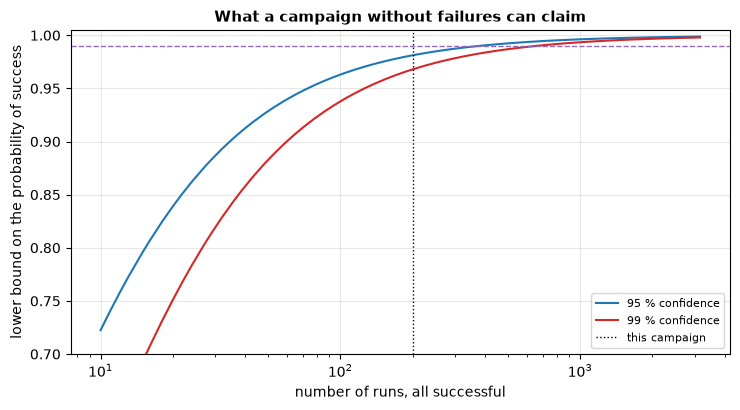

In [4]:
successes = int(campaign.success.sum())
lower, upper = campaign.success_interval(0.95)
print(f"successful dockings: {successes} of {campaign.n_runs}")
print(f"probability of success: {campaign.success_rate:.3f}, 95 % interval from {lower:.4f} to {upper:.4f}")

for seed, outcome, reason, violations in zip(campaign.seeds, campaign.outcomes, campaign.abort_reasons,
                                             campaign.violations):
    if outcome != "docked":
        print(f"  seed {seed}: {outcome}; {reason or ', '.join(violations)}")

trials = np.unique(np.round(np.logspace(1, 3.5, 60)).astype(int))
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for confidence, color in ((0.95, COL_ANA), (0.99, COL_NUM)):
    bound = [wilson_interval(k, k, confidence)[0] for k in trials]
    ax.semilogx(trials, bound, color=color, label=f"{confidence * 100:.0f} % confidence")
ax.axvline(campaign.n_runs, color="k", ls=":", lw=1, label="this campaign")
ax.axhline(0.99, color=COL_ZONE, ls="--", lw=1)
ax.set_ylim(0.7, 1.005)
ax.set_xlabel("number of runs, all successful")
ax.set_ylabel("lower bound on the probability of success")
ax.set_title("What a campaign without failures can claim")
ax.legend(fontsize=8)
fig.tight_layout()

z = 1.959964
print(f"runs without failures needed to claim 99 % at 95 % confidence: {int(np.ceil(0.99 / 0.01 * z**2))}")
print(f"runs without failures needed to claim 99.9 % at 95 % confidence: {int(np.ceil(0.999 / 0.001 * z**2))}")

Of the 200 runs, 199 end in a docking inside the limits and one ends in an abort. The observed frequency is 0.995. What the campaign supports is the interval: with 95 percent confidence the probability of success is between 0.972 and 0.999.

The plot puts this in perspective. A campaign cannot demonstrate a probability higher than its size allows: even without a single failure, 200 runs would support no more than 0.981, and demonstrating 0.99 takes 381 runs without failures, 0.999 almost four thousand. Each additional nine costs ten times as many runs. A campaign of this size describes the ordinary behaviour of the system. What it says about rare failures comes from looking closely at the ones it happens to find.

## The run that failed

Every run is identified by its seed, so the one that failed can be flown again, alone, and examined. The abort was commanded because the attitude error was too large, and the place to look is the hardware that this run drew.

seed 199: center of mass offset [-1.8  2.3 -7.6] mm (3.8 standard deviations on the worst axis)
torque of a burn at full thrust: 15 mN m; unloading couple: 8 mN m; wheel torque limit: 20 mN m



as flown:  aborted (attitude error too large); first wheel saturated at 342 s, 42 s into the departure burn; attitude error at the abort 12 deg
repaired:  docked; largest wheel momentum 0.42 N m s, propellant 477 g against 382 g


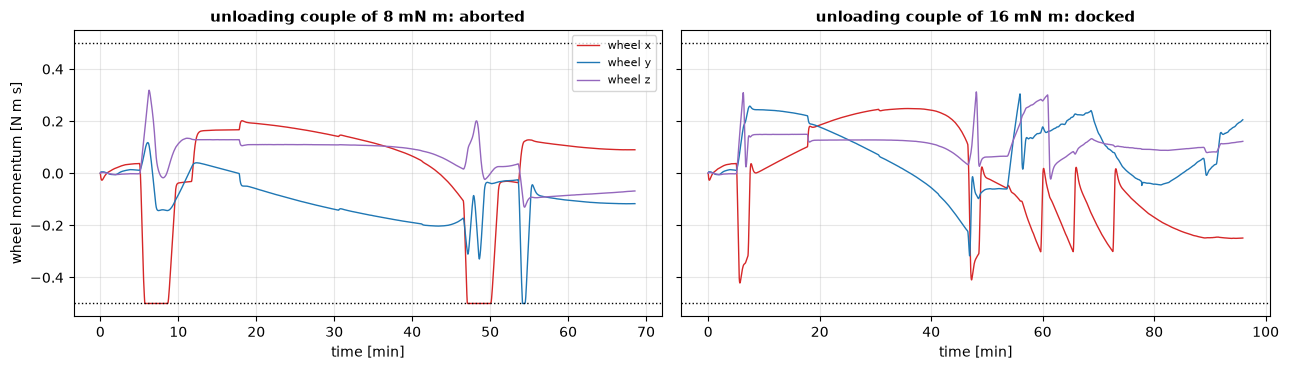

In [ ]:
from ios_mission_planner.gnc.mission_manager import Phase
from ios_mission_planner.sim.monte_carlo import sample_config

failed_seed = int(campaign.seeds[~campaign.success][0])
config = sample_config(base, dispersions, failed_seed)
wheels, thrusters = config.deputy.wheels, config.deputy.thrusters
offset = thrusters.center_of_mass_offset

print(f"seed {failed_seed}: center of mass offset {np.round(offset * 1e3, 1)} mm "
      f"({np.abs(offset).max() / dispersions.center_of_mass_offset:.1f} standard deviations on the worst axis)")
print(f"torque of a burn at full thrust: {thrusters.max_force * np.abs(offset).max() * 1e3:.0f} mN m; "
      f"unloading couple: {wheels.desaturation_torque * 1e3:.0f} mN m; wheel torque limit: {wheels.max_torque * 1e3:.0f} mN m")

failed = simulate(config)

stronger = sample_config(base, dispersions, failed_seed)
stronger.deputy.wheels.desaturation_torque = 0.016
repaired = simulate(stronger)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, run, name in ((axes[0], failed, "unloading couple of 8 mN m"), (axes[1], repaired, "unloading couple of 16 mN m")):
    for index, (axis_name, color) in enumerate((("x", COL_NUM), ("y", COL_ANA), ("z", COL_ZONE))):
        ax.plot(run.t / 60, run.wheel_momentum[:, index], color=color, lw=1.0, label=f"wheel {axis_name}")
    ax.axhline(wheels.max_momentum, color="k", ls=":", lw=1); ax.axhline(-wheels.max_momentum, color="k", ls=":", lw=1)
    ax.set_xlabel("time [min]"); ax.set_title(f"{name}: {run.outcome}")
axes[0].set_ylabel("wheel momentum [N m s]"); axes[0].legend(fontsize=8)
fig.tight_layout()

saturated = np.abs(failed.wheel_momentum).max(axis=1) >= 0.999 * wheels.max_momentum
abort = np.argmax(failed.phase == Phase.ABORT)
print(f"\nas flown:  {failed.outcome} ({failed.abort_reason}); first wheel saturated at {failed.t[np.argmax(saturated)]:.0f} s, "
      f"{failed.t[np.argmax(saturated)] - 300:.0f} s into the departure burn; attitude error at the abort "
      f"{np.degrees(failed.attitude_error[abort]):.0f} deg")
print(f"repaired:  {repaired.outcome}; largest wheel momentum {np.abs(repaired.wheel_momentum).max():.2f} N m s, "
      f"propellant {repaired.propellant_used * 1e3:.0f} g against {failed.propellant_used * 1e3:.0f} g")

The cause is a rare draw and a sizing error together. This run drew a center of mass 7.6 mm from the thrust lines on one axis, almost four standard deviations. During a burn at full thrust that offset produces a torque of 15 mN m, and the momentum manager unloads the wheels with a couple of 8 mN m, half of what was arriving. The wheel was full 42 seconds into the departure burn. A wheel at its limit no longer controls its axis: the attitude was lost during the burns, and the abort was commanded, with an attitude error of 12 degrees, as soon as the monitoring of the approach became active. With an unloading couple of 16 mN m the same run docks, and the wheels stay below 0.42 N m s.

The failure is not bad luck to be averaged away. It reveals a rule that the design did not respect: the unloading torque must exceed the largest disturbance torque that the thrusters can produce, the thrust times the largest credible offset of the center of mass, while staying below what the wheel can oppose. The reference configuration keeps the original value, so that the campaign above remains reproducible. A design iteration would adopt the larger one and fly the campaign again.

## Conditions at contact

Each histogram shows one contact condition over all the runs that reached the port, with its limit.

condition                           mean       std  99th pct     worst   limit      worst / limit
lateral misalignment [m]          0.0016    0.0013    0.0049    0.0138   0.1        0.138
axial speed [m/s]                 0.0756    0.0003    0.0764 0.0749 to 0.0765   (0.05, 0.1)
lateral speed [m/s]               0.0005    0.0003    0.0012    0.0017   0.04       0.042
angular misalignment [deg]        0.3692    0.2030    0.8712    1.4251   4.0        0.356
roll misalignment [deg]           0.2318    0.1599    0.6073    0.6915   4.0        0.173
angular rate [deg/s]              0.0011    0.0050    0.0025    0.0592   0.2        0.296


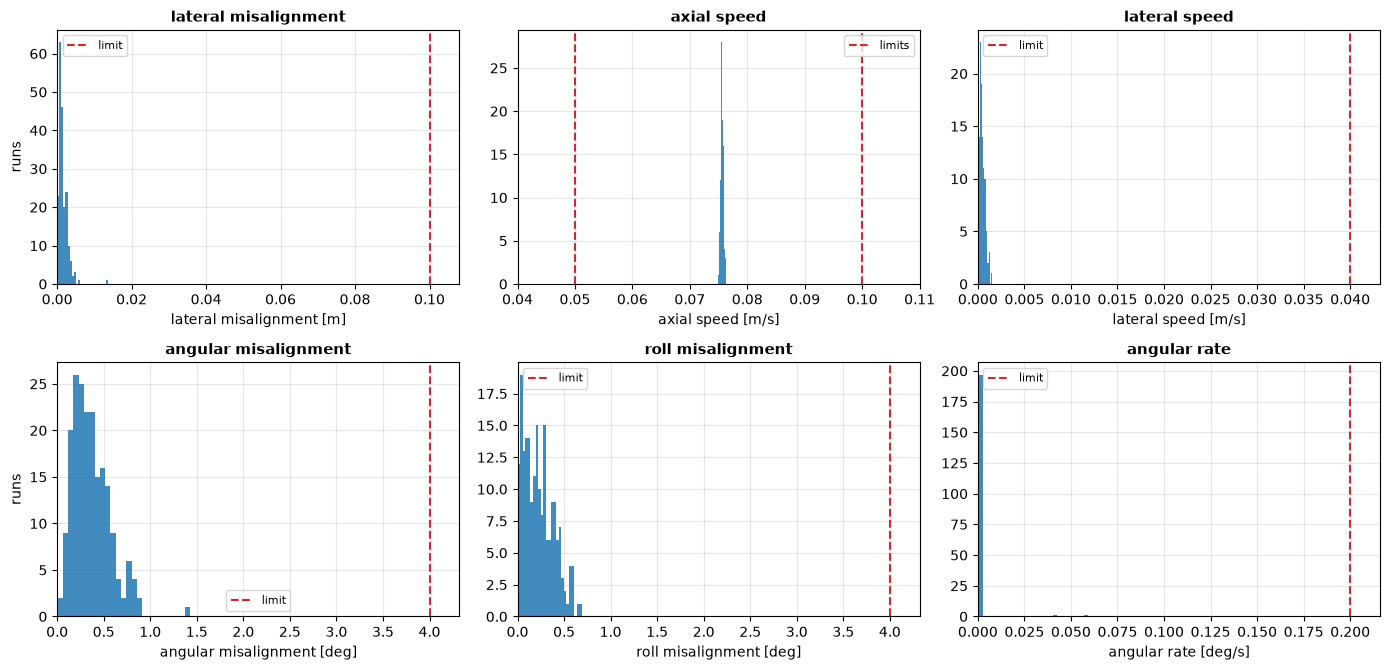

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6.8))
reached = ~np.isnan(campaign.contact[:, 0])

for ax, (column, name) in zip(axes.ravel(), enumerate(CONTACT_QUANTITIES)):
    values = campaign.contact[reached, column]
    limit = campaign.limits[name]
    ax.hist(values, bins=25, color=COL_ANA, alpha=0.85)
    if isinstance(limit, tuple):
        ax.axvline(limit[0], color=COL_NUM, ls="--"); ax.axvline(limit[1], color=COL_NUM, ls="--", label="limits")
        ax.set_xlim(limit[0] - 0.01, limit[1] + 0.01)
    else:
        ax.axvline(limit, color=COL_NUM, ls="--", label="limit")
        ax.set_xlim(0, limit * 1.08)
    ax.set_xlabel(name); ax.set_title(name.split(" [")[0])
    ax.legend(fontsize=8)
axes[0, 0].set_ylabel("runs"); axes[1, 0].set_ylabel("runs")
fig.tight_layout()

print(f"{'condition':30s} {'mean':>9s} {'std':>9s} {'99th pct':>9s} {'worst':>9s}   limit      worst / limit")
for name, s in campaign.contact_statistics().items():
    limit = campaign.limits[name]
    if isinstance(limit, tuple):
        print(f"{name:30s} {s['mean']:9.4f} {s['std']:9.4f} {s['p99']:9.4f} {s['min']:.4f} to {s['max']:.4f}   {limit}")
    else:
        print(f"{name:30s} {s['mean']:9.4f} {s['std']:9.4f} {s['p99']:9.4f} {s['max']:9.4f}   {limit:<10} {s['max'] / limit:.3f}")

No run comes close to a limit. The lateral offset at contact is 1.6 mm on average and 14 mm in the worst run, a seventh of the limit. The axial speed stays within a millimetre per second of the commanded value, and the lateral speed is negligible. The reason is the one seen in the closed-loop notebook: the relative sensor becomes more accurate as the distance shrinks, and the thrusters resolve a quarter of a millimetre per second, so the dispersion at the port is set by the last metres and not by the errors at the start.

The angular quantities use more of their limits, for a reason that has nothing to do with control. The mean angular misalignment, 0.37 degrees, is the attitude error of the chief itself, which the deputy cannot see: its sensor measures where the target is and not how the port is oriented, so the deputy aligns with the direction in which the port should be pointing. The worst case, 1.4 degrees, is a third of the limit. The angular rate reaches 30 percent of its limit in the worst run and is a hundred times smaller in a typical one.

## Propellant

The velocity change of the nominal run is one number. The budget needs the distribution: the mean says what the mission will probably cost, a high percentile says what must be on board.

total delta-v: mean 6.175 m/s, std 0.170, median 6.158, 99th percentile 6.579, worst 6.654
99th percentile over the nominal run: +8.6 %
propellant: mean 459 g, worst 499 g
  hold at S1                 mean 0.108  std 0.039  max 0.291
  transfer S1 to S2          mean 3.704  std 0.113  max 4.247
  hold at S2                 mean 0.084  std 0.021  max 0.158
  forced approach S2 to S3   mean 2.070  std 0.151  max 2.299
  hold at S3                 mean 0.045  std 0.005  max 0.062
  final approach             mean 0.161  std 0.012  max 0.177
largest wheel momentum over the campaign: 0.50 N m s of 0.5


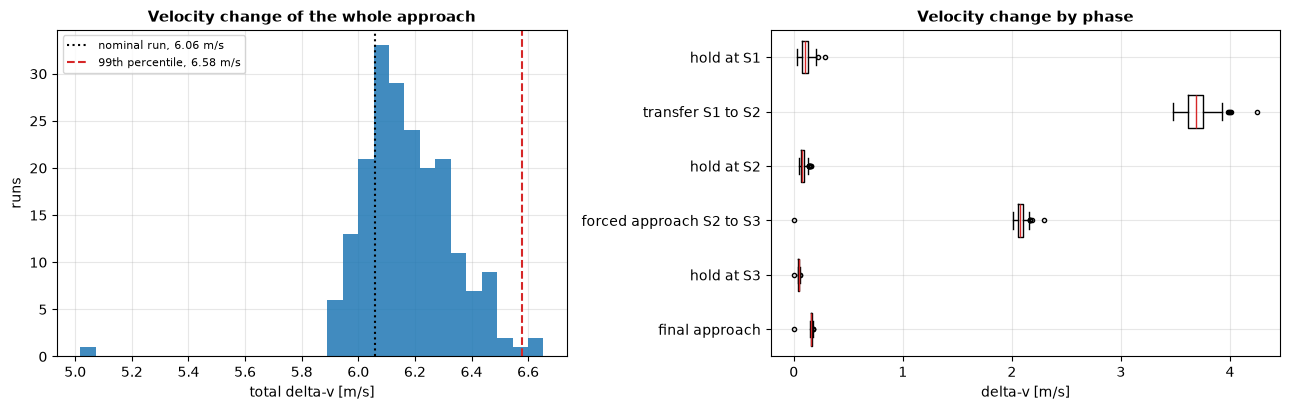

In [6]:
nominal = simulate(SimulationConfig(seed=1))
dv = campaign.delta_v
p50, p99 = np.percentile(dv, [50, 99])

phases = [k for k in campaign.delta_v_by_phase[0] if k != "docked"]
by_phase = np.array([[run.get(k, 0.0) for k in phases] for run in campaign.delta_v_by_phase])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(dv, bins=30, color=COL_ANA, alpha=0.85)
axes[0].axvline(nominal.total_delta_v, color="k", ls=":", label=f"nominal run, {nominal.total_delta_v:.2f} m/s")
axes[0].axvline(p99, color=COL_NUM, ls="--", label=f"99th percentile, {p99:.2f} m/s")
axes[0].set_xlabel("total delta-v [m/s]"); axes[0].set_ylabel("runs")
axes[0].set_title("Velocity change of the whole approach")
axes[0].legend(fontsize=8)

axes[1].boxplot(by_phase, orientation="horizontal", tick_labels=phases, widths=0.6,
                medianprops={"color": COL_NUM}, flierprops={"markersize": 3})
axes[1].invert_yaxis()
axes[1].set_xlabel("delta-v [m/s]")
axes[1].set_title("Velocity change by phase")
fig.tight_layout()

print(f"total delta-v: mean {dv.mean():.3f} m/s, std {dv.std():.3f}, median {p50:.3f}, "
      f"99th percentile {p99:.3f}, worst {dv.max():.3f}")
print(f"99th percentile over the nominal run: +{(p99 / nominal.total_delta_v - 1) * 100:.1f} %")
print(f"propellant: mean {campaign.propellant.mean() * 1e3:.0f} g, worst {campaign.propellant.max() * 1e3:.0f} g")
for name, column in zip(phases, by_phase.T):
    print(f"  {name:26s} mean {column.mean():.3f}  std {column.std():.3f}  max {column.max():.3f}")
print(f"largest wheel momentum over the campaign: {campaign.max_wheel_momentum.max():.2f} N m s of 0.5")

The approach costs 6.18 m/s on average, with a standard deviation of 0.17 m/s, and 6.58 m/s at the 99th percentile, 8.6 percent above the nominal run. That percentage is the margin that the budget should carry for this phase, obtained from the mission itself and not from a rule of thumb.

The spread comes almost entirely from the two phases that dominate the consumption, the transfer and the forced approach, where the thruster errors act on long firings. The phases at the port, which demand the most from navigation and control, are cheap in propellant and almost constant. The largest wheel momentum of the campaign is the full capacity of a wheel, and it belongs to the run that failed.

## The trajectories

All the runs in the orbit plane, and the last 600 m.

spread of the starting points: 20 m along-track, 20 m radial
largest radial excursion inside the last 600 m: 317.5 m


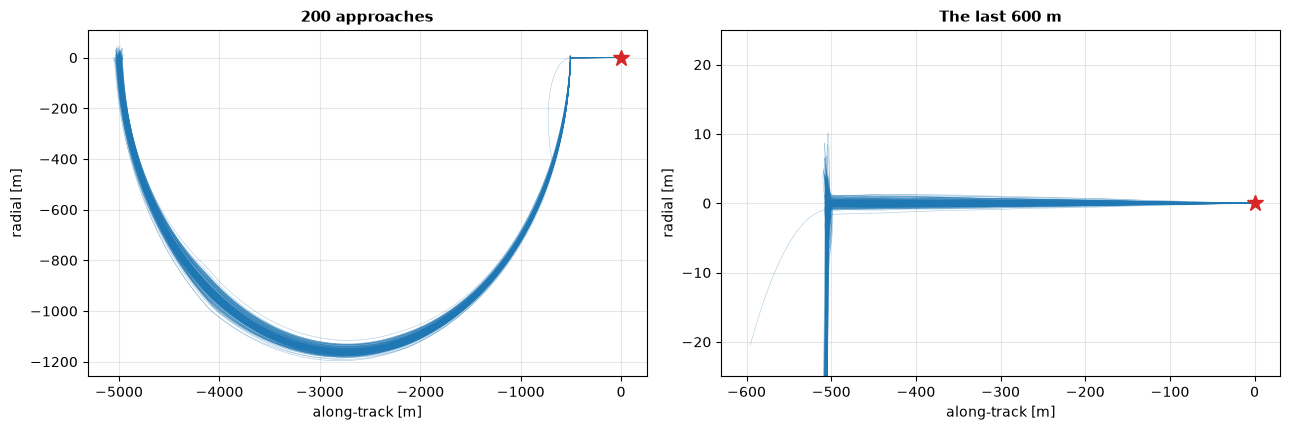

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for trajectory in campaign.trajectories:
    axes[0].plot(trajectory[:, 1], trajectory[:, 0], color=COL_ANA, lw=0.4, alpha=0.4)
    near = trajectory[:, 1] > -600
    axes[1].plot(trajectory[near, 1], trajectory[near, 0], color=COL_ANA, lw=0.4, alpha=0.4)
for ax in axes:
    ax.plot(0, 0, "*", color=COL_NUM, ms=12)
    ax.set_xlabel("along-track [m]"); ax.set_ylabel("radial [m]")
axes[0].set_title(f"{campaign.n_runs} approaches")
axes[1].set_title("The last 600 m")
axes[1].set_ylim(-25, 25)
fig.tight_layout()

start = np.array([t[0] for t in campaign.trajectories])
arrival = np.array([np.abs(t[t[:, 1] > -600][:, 0]).max() for t in campaign.trajectories])
print(f"spread of the starting points: {start[:, 1].std():.0f} m along-track, {start[:, 0].std():.0f} m radial")
print(f"largest radial excursion inside the last 600 m: {arrival.max():.1f} m")

The starting points are spread by 20 m on each axis, and the first navigation estimates are wrong by more. All the runs converge on the same arc, arrive at S2 within metres, and fly the forced approach inside a tube that narrows toward the port. The radial excursion of hundreds of metres printed above belongs to the end of the transfer arc, which reaches S2 from below, and the thin line that leaves the bundle near S2 is the run that aborted.

The dispersion does not grow along the approach, it shrinks, because every phase observes and corrects what the previous one left. This is the difference between this campaign and the linear propagation of the safety chapter, in which nothing is corrected and every initial error grows for the whole duration.

## Where the design breaks

A campaign in which everything works shows that the design has margin; it does not show where the margin ends. The way to find out is to degrade one thing at a time and repeat the campaign. Each case below changes a single element of the scenario and flies a smaller campaign, enough to tell a design that still works from one that does not.

In [8]:
def no_momentum_management(config, d):
    config.deputy.wheels.desaturation_enabled = False

def noisy_sensor(config, d):
    config.deputy.sensors.relative_angle_noise_std *= 10.0
    config.deputy.sensors.relative_range_noise_floor *= 10.0

def coarse_thrusters(config, d):
    config.deputy.thrusters.min_impulse_bit *= 25.0

def narrow_field_of_view(config, d):
    config.deputy.sensors.relative_fov_half_angle_deg = 3.0

def tumbling_chief(config, d):
    d.chief_attitude_error *= 10.0

def poor_thrusters(config, d):
    d.thruster_scale_error *= 4.0
    d.thruster_misalignment *= 4.0

cases = {
    "baseline": None,
    "no momentum management": no_momentum_management,
    "relative sensor 10 times noisier": noisy_sensor,
    "minimum impulse bit 25 times larger": coarse_thrusters,
    "field of view of 3 degrees half-angle": narrow_field_of_view,
    "attitude error of the chief 10 times larger": tumbling_chief,
    "thruster errors 4 times larger": poor_thrusters,
}

N_STRESS = 48
stress = {}
started = time.perf_counter()
for name, change in cases.items():
    config, d = copy.deepcopy(base), copy.deepcopy(dispersions)
    if change is not None:
        change(config, d)
    stress[name] = run_monte_carlo(config, d, n_runs=N_STRESS, first_seed=1001, workers=WORKERS)
print(f"{len(cases)} campaigns of {N_STRESS} runs in {(time.perf_counter() - started) / 60:.1f} min\n")

print(f"{'case':46s} {'success':>8s}  95 % interval    lateral [m]  angular [deg]  delta-v [m/s]   other outcomes")
for name, c in stress.items():
    low, high = c.success_interval()
    reached = ~np.isnan(c.contact[:, 0])
    lateral = np.nanmax(c.contact[:, 0]) if reached.any() else np.nan
    angular = np.nanmax(c.contact[:, 3]) if reached.any() else np.nan
    reasons = {}
    for outcome, reason, violations in zip(c.outcomes, c.abort_reasons, c.violations):
        if outcome != "docked":
            key = reason or ", ".join(v.split(" [")[0] for v in violations) or outcome
            reasons[key] = reasons.get(key, 0) + 1
    print(f"{name:46s} {c.success_rate:8.2f}  {low:.2f} to {high:.2f}   {lateral:10.4f}  {angular:12.3f}  "
          f"{np.percentile(c.delta_v, 99):12.2f}   {reasons or ''}")

7 campaigns of 48 runs in 9.2 min

case                                            success  95 % interval    lateral [m]  angular [deg]  delta-v [m/s]   other outcomes
baseline                                           1.00  0.93 to 1.00       0.0166         1.857          6.61   
no momentum management                             0.21  0.12 to 0.34       0.0039         0.599         11.11   {'relative measurements lost': 26, 'attitude error too large': 12}
relative sensor 10 times noisier                   1.00  0.93 to 1.00       0.0090         0.875          7.03   
minimum impulse bit 25 times larger                1.00  0.93 to 1.00       0.0345         0.853         49.96   
field of view of 3 degrees half-angle              1.00  0.93 to 1.00       0.0166         1.857          6.57   
attitude error of the chief 10 times larger        0.48  0.34 to 0.62       0.0379         8.645          6.61   {'roll misalignment': 7, 'angular misalignment, roll misalignment': 5, 'angular mis

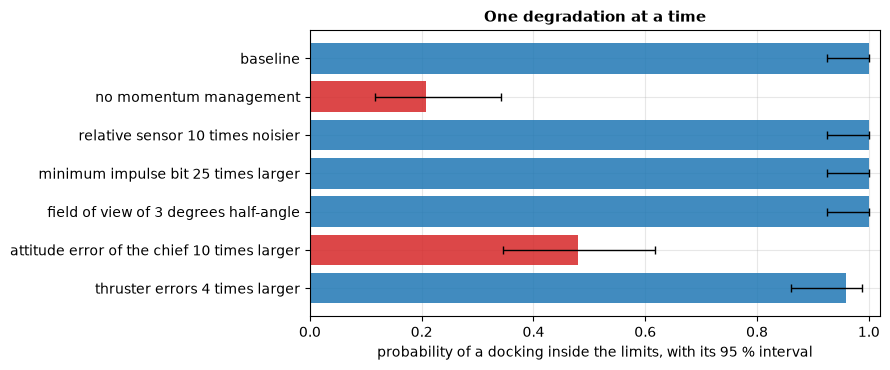

In [9]:
names = list(stress)
rates = np.array([stress[k].success_rate for k in names])
bounds = np.array([stress[k].success_interval() for k in names])

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(names, rates, color=[COL_ANA if r > 0.9 else COL_NUM for r in rates], alpha=0.85)
xerr = np.clip([rates - bounds[:, 0], bounds[:, 1] - rates], 0.0, None)
ax.errorbar(rates, np.arange(len(names)), xerr=xerr, fmt="none",
            ecolor="k", capsize=3, lw=1)
ax.invert_yaxis()
ax.set_xlim(0, 1.02)
ax.set_xlabel("probability of a docking inside the limits, with its 95 % interval")
ax.set_title("One degradation at a time")
fig.tight_layout()

A campaign of 48 runs cannot distinguish a probability of 1.00 from one of 0.95, as the intervals show. It is enough to separate what works from what does not, and each case says something different.

Without momentum management the mission fails four times out of five. With a center of mass offset of 2 mm at one sigma the wheels saturate during the burns in most runs, and the mission survives only when the offset happens to be small. This one function is the difference between a design that works and one that does not.

A relative sensor ten times noisier does not change the outcome and costs 0.4 m/s more at the 99th percentile, spent following the noise. A field of view of 3 degrees instead of 20 changes nothing at all: the attitude control keeps the target within a fraction of a degree of the optical axis, so the field of view of the reference sensor has a wide margin.

Thrusters with a minimum impulse bit 25 times larger, 1 N s, still dock inside the limits, with a lateral offset at contact that doubles. The cost is elsewhere: the velocity change at the 99th percentile rises from 6.6 to 50 m/s. The limit cycle described in the control notebook, summed over an hour and a half of holds and forced motion, multiplies the propellant by eight. The docking tolerates coarse thrusters and the budget does not.

Thruster errors four times larger, 12 percent in scale and 2 degrees in alignment, bring the success rate to 0.96 and more than double the propellant. Both failures are aborts for an excessive closing speed: the monitoring did its job when the thrust delivered was too far from the thrust commanded.

An attitude error of the chief ten times larger, 3 degrees at one sigma, halves the success rate, and every failure is an angular misalignment at contact. No change to the deputy would help, because the deputy does not measure the orientation of the port. A target that cannot hold its attitude within about a degree needs a sensor that measures the relative attitude, and a guidance that aligns with the port as it is and not as it should be.

## Summary

`run_monte_carlo` flies the closed-loop simulation with dispersed hardware and initial conditions, on several processes, and `wilson_interval` turns the count of successes into a statement with a confidence. For the reference mission 199 of 200 runs dock inside the limits: the probability of success is between 0.972 and 0.999 with 95 percent confidence, the conditions at contact stay below 36 percent of their limits, and the approach costs 6.6 m/s at the 99th percentile, 8.6 percent more than the nominal run.

The single failure and the stress cases say more than the count. The run that failed exposed an undersized momentum unloading, with a specific rule to correct it. The stress cases rank what the mission depends on: the momentum management and the attitude stability of the target decide whether the docking succeeds, the resolution and the accuracy of the thrusters decide what it costs, and the noise and the field of view of the relative sensor, within wide limits, decide neither.

These numbers are conditional on the dispersions assumed, normal and independent, and on the models of the simulation. They describe the ordinary behaviour of the system. Failures of components are not in the sample; they are covered by the injected failure cases of the closed-loop notebook.